# Phase 1 — Data Pipeline

Extends Lessons 0.1–0.3 (which worked on a single sample image) to the full ShanghaiTech Part A dataset: download all images, build a density map for every one, cache the results, and sanity-check the whole set.

In [1]:
import os
import time
import json
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
from scipy.io import loadmat
from scipy.ndimage import gaussian_filter
import matplotlib.pyplot as plt

DATA_DIR = Path("../data/shanghaitech")
PART_A_DIR = DATA_DIR / "ShanghaiTech" / "part_A"
PROCESSED_DIR = Path("../data/processed/part_A")
SIGMA = 15  # same fixed-width Gaussian as Lesson 0.3

print("numpy", np.__version__)
print("data dir:", DATA_DIR.resolve())


numpy 2.5.2
data dir: C:\Users\ravip\Desktop\Crowdcast\data\shanghaitech


## 1. Download the full dataset

Only the single sample image was downloaded before. This pulls the whole ShanghaiTech dataset (~349 MB, Kaggle mirror `tthien/shanghaitech`) and skips the download if it's already present.

In [2]:
if PART_A_DIR.exists():
    print("Dataset already present, skipping download.")
else:
    import kaggle
    kaggle.api.authenticate()
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    start = time.time()
    kaggle.api.dataset_download_files(
        "tthien/shanghaitech", path=str(DATA_DIR), unzip=True, quiet=False
    )
    print(f"Downloaded and unzipped in {time.time() - start:.1f}s")

print("part_A exists:", PART_A_DIR.exists())


Dataset already present, skipping download.
part_A exists: True


## 2. Explore the directory structure

Confirm the layout matches what's documented in `DATASETS.md`, and count how many images are actually in each split.

In [3]:
splits = {
    "train": PART_A_DIR / "train_data",
    "test": PART_A_DIR / "test_data",
}

for name, split_dir in splits.items():
    images_dir = split_dir / "images"
    gt_dir = split_dir / "ground-truth"
    n_images = len(list(images_dir.glob("*.jpg")))
    n_gt = len(list(gt_dir.glob("*.mat")))
    print(f"{name}: {n_images} images, {n_gt} ground-truth files")


train: 300 images, 300 ground-truth files
test: 182 images, 182 ground-truth files


## 3. Density map function

Same approach as `learning/lesson_03_density_map.py`, generalized to take any image/mat pair instead of the one hardcoded sample.

In [4]:
def load_points(mat_path):
    mat = loadmat(str(mat_path))
    info = mat["image_info"][0, 0][0, 0]
    points = info["location"]
    stated_count = int(info["number"][0, 0])
    return points, stated_count


def build_density_map(image_shape, points, sigma=SIGMA):
    height, width = image_shape[:2]
    point_map = np.zeros((height, width), dtype=np.float32)
    for x, y in points:
        col, row = int(round(x)), int(round(y))
        if 0 <= row < height and 0 <= col < width:
            point_map[row, col] += 1
    return gaussian_filter(point_map, sigma=sigma)


def gt_path_for(image_path):
    # IMG_42.jpg -> GT_IMG_42.mat, swapping the images/ dir for ground-truth/
    name = "GT_" + image_path.stem + ".mat"
    return image_path.parents[1] / "ground-truth" / name


## 4. Sanity check against the known Lesson 0.3 result

`IMG_1.jpg` in the test set should still give 172 points and a density map summing to 172.0, exactly like the lesson script found on the standalone sample copy.

In [5]:
sample_img_path = splits["test"] / "images" / "IMG_1.jpg"
sample_mat_path = gt_path_for(sample_img_path)

img = np.array(Image.open(sample_img_path))
points, stated_count = load_points(sample_mat_path)
density = build_density_map(img.shape, points)

print("stated count:", stated_count)
print("points loaded:", len(points))
print("density map sum:", round(density.sum(), 4))
assert len(points) == stated_count == 172
assert abs(density.sum() - 172.0) < 0.01
print("Matches Lesson 0.3 result.")


stated count: 172
points loaded: 172
density map sum: 172.0
Matches Lesson 0.3 result.


## 5. Batch-process every image in Part A

For each split (train/test), build a density map for every image, cache it as a `.npy` file, and record (image path, density map path, count) in a manifest. This is the step that turns "it works on one image" into an actual usable dataset.

In [6]:
def process_split(split_name, split_dir, sigma=SIGMA):
    images_dir = split_dir / "images"
    out_dir = PROCESSED_DIR / split_name / "density_maps"
    out_dir.mkdir(parents=True, exist_ok=True)

    rows = []
    image_paths = sorted(images_dir.glob("*.jpg"))
    start = time.time()

    for image_path in image_paths:
        mat_path = gt_path_for(image_path)
        img = np.array(Image.open(image_path))
        points, stated_count = load_points(mat_path)
        density = build_density_map(img.shape, points, sigma=sigma)

        density_path = out_dir / (image_path.stem + ".npy")
        np.save(density_path, density)

        rows.append({
            "image_path": str(image_path),
            "density_map_path": str(density_path),
            "stated_count": stated_count,
            "points_loaded": len(points),
            "density_sum": float(density.sum()),
            "height": img.shape[0],
            "width": img.shape[1],
        })

    elapsed = time.time() - start
    df = pd.DataFrame(rows)
    print(f"{split_name}: processed {len(df)} images in {elapsed:.1f}s ({elapsed/len(df):.2f}s/image)")
    return df


train_df = process_split("train", splits["train"])
test_df = process_split("test", splits["test"])


train: processed 300 images in 46.3s (0.15s/image)


test: processed 182 images in 28.3s (0.16s/image)


## 6. Sanity-check the whole dataset

The Lesson 0.3 invariant (`points_loaded == stated_count`, `density_sum ≈ stated_count`) should hold for every image, not just the one we spot-checked earlier.

In [7]:
for name, df in [("train", train_df), ("test", test_df)]:
    mismatched_points = (df["points_loaded"] != df["stated_count"]).sum()
    bad_sums = (df["density_sum"] - df["stated_count"]).abs().gt(0.5).sum()

    print(f"--- {name} ---")
    print(f"images: {len(df)}")
    print(f"count range: {df['stated_count'].min()} - {df['stated_count'].max()}, "
          f"mean {df['stated_count'].mean():.1f}")
    print(f"images where points_loaded != stated_count: {mismatched_points}")
    print(f"images where |density_sum - stated_count| > 0.5: {bad_sums}")
    print()

assert (train_df["points_loaded"] == train_df["stated_count"]).all()
assert (test_df["points_loaded"] == test_df["stated_count"]).all()
print("All images pass the point-count / density-sum invariant.")


--- train ---
images: 300
count range: 33 - 3138, mean 541.4
images where points_loaded != stated_count: 0
images where |density_sum - stated_count| > 0.5: 13

--- test ---
images: 182
count range: 66 - 2256, mean 433.3
images where points_loaded != stated_count: 0
images where |density_sum - stated_count| > 0.5: 11

All images pass the point-count / density-sum invariant.


### 6b. Why do some images have `density_sum < stated_count`?

`points_loaded == stated_count` held for every image, but `density_sum` (which only counts points that landed inside the image array) didn't always match. That gap can only come from points whose `(x, y)` coordinate falls outside the image bounds — investigate directly instead of guessing.

In [8]:
def count_out_of_bounds(row):
    points, _ = load_points(gt_path_for(Path(row["image_path"])))
    h, w = row["height"], row["width"]
    in_bounds = sum(1 for x, y in points if 0 <= round(y) < h and 0 <= round(x) < w)
    return len(points) - in_bounds

for name, df in [("train", train_df), ("test", test_df)]:
    mismatched = df[(df["density_sum"] - df["stated_count"]).abs() > 0.5].copy()
    mismatched["out_of_bounds_points"] = mismatched.apply(count_out_of_bounds, axis=1)
    print(f"--- {name}: {len(mismatched)} mismatched images ---")
    print(mismatched[["image_path", "stated_count", "density_sum", "out_of_bounds_points"]]
          .assign(image_path=lambda d: d["image_path"].apply(lambda p: Path(p).name))
          .to_string(index=False))
    print()


--- train: 13 mismatched images ---
 image_path  stated_count  density_sum  out_of_bounds_points
IMG_151.jpg           987        985.0                     2
IMG_165.jpg           468        467.0                     1
IMG_177.jpg           578        577.0                     1
IMG_186.jpg          1655       1653.0                     2
IMG_204.jpg           549        548.0                     1
IMG_219.jpg           426        425.0                     1
IMG_231.jpg           443        442.0                     1
IMG_246.jpg           373        372.0                     1
IMG_251.jpg          1205       1203.0                     2
 IMG_28.jpg           814        813.0                     1
 IMG_75.jpg           296        295.0                     1
 IMG_92.jpg          2650       2649.0                     1
 IMG_93.jpg           273        272.0                     1



--- test: 11 mismatched images ---
 image_path  stated_count  density_sum  out_of_bounds_points
 IMG_10.jpg           502        501.0                     1
IMG_121.jpg          1210       1209.0                     1
IMG_131.jpg           604        603.0                     1
IMG_137.jpg           489        488.0                     1
IMG_154.jpg           495        494.0                     1
 IMG_17.jpg          1156       1155.0                     1
IMG_170.jpg           670        669.0                     1
 IMG_47.jpg           316        315.0                     1
 IMG_54.jpg           529        528.0                     1
  IMG_6.jpg           361        360.0                     1
  IMG_7.jpg           568        567.0                     1



## 7. Save manifests

These CSVs are what the training pipeline (Phase 3+) will actually load from — one row per image, pointing at its cached density map.

In [9]:
train_manifest_path = PROCESSED_DIR / "manifest_train.csv"
test_manifest_path = PROCESSED_DIR / "manifest_test.csv"

train_df.to_csv(train_manifest_path, index=False)
test_df.to_csv(test_manifest_path, index=False)

print("saved:", train_manifest_path)
print("saved:", test_manifest_path)
train_df.head()


saved: ..\data\processed\part_A\manifest_train.csv
saved: ..\data\processed\part_A\manifest_test.csv


,image_path,density_map_path,stated_count,points_loaded,density_sum,height,width
0,..\data\shanghaitech\ShanghaiTech\part_A\train...,..\data\processed\part_A\train\density_maps\IM...,1546,1546,1545.999878,768,1024
1,..\data\shanghaitech\ShanghaiTech\part_A\train...,..\data\processed\part_A\train\density_maps\IM...,920,920,920.000000,683,1024
2,..\data\shanghaitech\ShanghaiTech\part_A\train...,..\data\processed\part_A\train\density_maps\IM...,371,371,371.000000,654,1024
3,..\data\shanghaitech\ShanghaiTech\part_A\train...,..\data\processed\part_A\train\density_maps\IM...,298,298,298.000000,768,1024
4,..\data\shanghaitech\ShanghaiTech\part_A\train...,..\data\processed\part_A\train\density_maps\IM...,184,184,183.999985,768,1024


## 8. Visual spot-check across the dataset

Lesson 0.3 only ever showed one density map. Here are a few random train images at different crowd sizes, to eyeball that the pipeline holds up beyond the single sample we've been staring at.

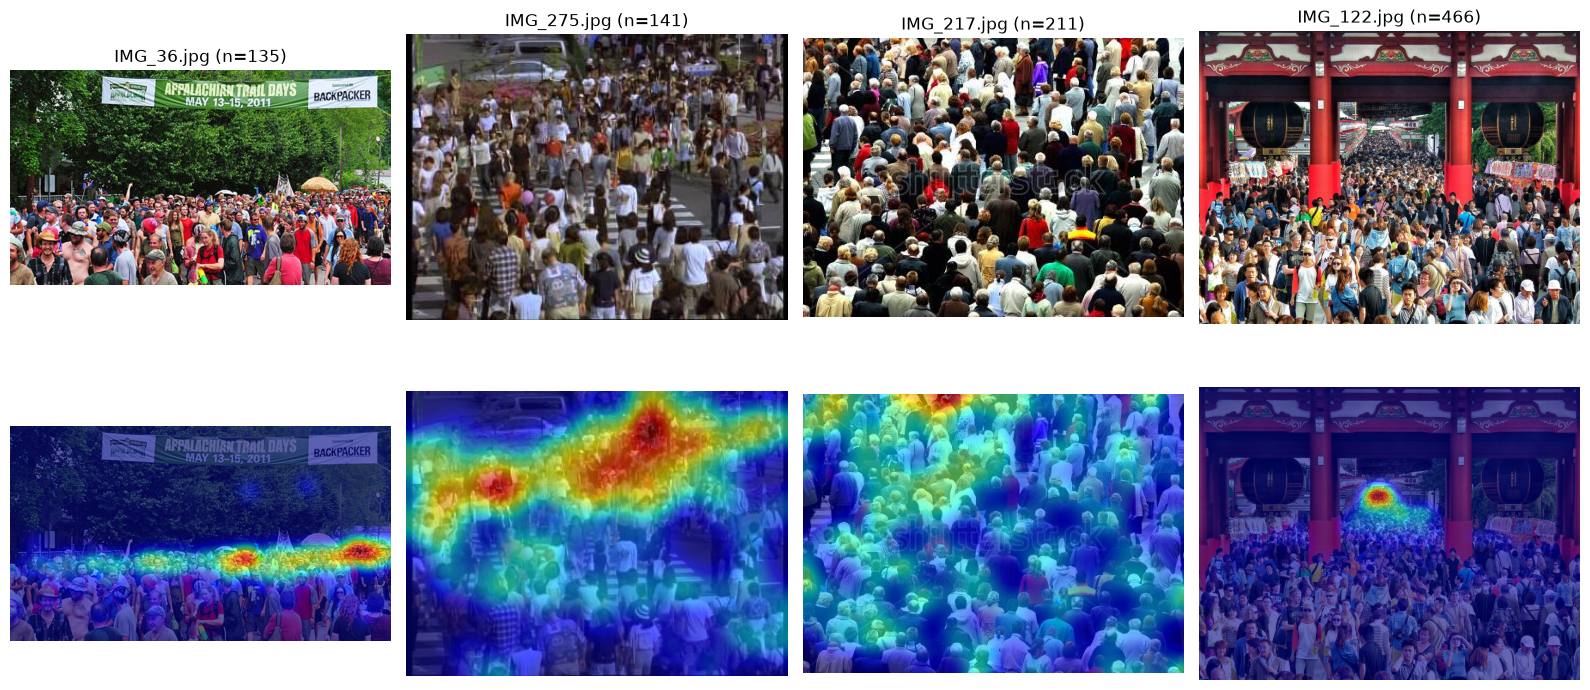

In [10]:
rng = np.random.default_rng(42)
sample_rows = train_df.loc[rng.choice(train_df.index, size=4, replace=False)].sort_values("stated_count")

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for col, (_, row) in enumerate(sample_rows.iterrows()):
    img = np.array(Image.open(row["image_path"]))
    density = np.load(row["density_map_path"])

    axes[0, col].imshow(img)
    axes[0, col].set_title(f"{Path(row['image_path']).name} (n={row['stated_count']})")
    axes[0, col].axis("off")

    axes[1, col].imshow(img)
    axes[1, col].imshow(density, cmap="jet", alpha=0.6)
    axes[1, col].axis("off")

plt.tight_layout()
plt.savefig(PROCESSED_DIR / "spot_check.png", dpi=100)
plt.show()


## Summary

Phase 1 output: `data/processed/part_A/{train,test}/density_maps/*.npy` plus `manifest_train.csv` / `manifest_test.csv`, each row = one image, its cached density map, and its ground-truth count. This is what Phase 3's training loop will read from directly, instead of recomputing density maps every run.

**Dataset stats:** 300 train images (33-3138 people, mean 541), 182 test images (66-2256 people, mean 433).

**Known caveat:** in 24/482 images (~5%), 1-2 annotated head points fall just outside the image's pixel bounds (confirmed in section 6b: `out_of_bounds_points` exactly accounts for every `stated_count` vs `density_sum` gap). This is noise in ShanghaiTech's own ground truth, not a bug in this pipeline — those points are dropped rather than clamped into the image, so `stated_count` is used as the training label (not `density_sum`) wherever the two differ.